In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# KAN-25 · Dataset dan Training Model Regresi Durasi

## Bagian A · OULAD

**Dataset:** Open University Learning Analytics Dataset (OULAD)
**Sumber:** https://research.stem.open.ac.uk/ouanalyse/open-dataset-more/
**Lisensi:** CC-BY 4.0
**Lokasi lokal:** `datasheet/raw/oulad/` (tidak di-commit)

In [2]:
RAW = Path("../datasheet/raw/oulad")

files = ["assessments", "courses", "studentAssessment", "studentInfo", "studentRegistration", "vle"]
df = {name: pd.read_csv(RAW / f"{name}.csv") for name in files}

for name, d in df.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")


=== assessments | 206 baris x 6 kolom
date    11

=== courses | 22 baris x 3 kolom
tidak ada missing value

=== studentAssessment | 173,912 baris x 5 kolom
score    173

=== studentInfo | 32,593 baris x 12 kolom
imd_band    1111

=== studentRegistration | 32,593 baris x 5 kolom
date_registration         45
date_unregistration    22521

=== vle | 6,364 baris x 6 kolom
week_from    5243
week_to      5243


In [3]:
asm = df["assessments"]
sa = df["studentAssessment"]

print("=== Jenis assessment:")
print(asm["assessment_type"].value_counts(), "\n")

print("=== Assessment yang date-nya kosong:")
print(asm[asm["date"].isna()]["assessment_type"].value_counts(), "\n")

print("=== Contoh isi studentAssessment:")
print(sa.head(), "\n")

print("=== is_banked:")
print(sa["is_banked"].value_counts())

=== Jenis assessment:
assessment_type
TMA     106
CMA      76
Exam     24
Name: count, dtype: int64 

=== Assessment yang date-nya kosong:
assessment_type
Exam    11
Name: count, dtype: int64 

=== Contoh isi studentAssessment:
   id_assessment  id_student  date_submitted  is_banked  score
0           1752       11391              18          0   78.0
1           1752       28400              22          0   70.0
2           1752       31604              17          0   72.0
3           1752       32885              26          0   69.0
4           1752       38053              19          0   79.0 

=== is_banked:
is_banked
0    172003
1      1909
Name: count, dtype: int64


## Cleaning 1: Buang baris banked
Baris `is_banked = 1` adalah nilai yang dibawa dari periode sebelumnya
(mahasiswa mengulang), bukan tugas yang benar-benar dikerjakan.

In [4]:
sa_clean = sa[sa["is_banked"] == 0]
print(len(sa), "→", len(sa_clean))

173912 → 172003


In [5]:
data = sa_clean.merge(asm, on="id_assessment", how="left")

print(data.shape)
print(data["assessment_type"].value_counts())
data.head()

(172003, 10)
assessment_type
TMA     97088
CMA     69956
Exam     4959
Name: count, dtype: int64


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


## Cleaning 2: Buang Exam + cek kualitas data
Exam dijadwalkan pada hari yang sama untuk semua mahasiswa,
jadi tidak mencerminkan durasi pengerjaan tugas.

In [6]:
# 1. Buang Exam
data = data[data["assessment_type"] != "Exam"]
print("Jumlah baris:", len(data))
print(data["assessment_type"].value_counts(), "\n")

# 2. Cek: masih ada deadline kosong?
print("Deadline kosong:", data["date"].isna().sum())

# 3. Cek: ada data dobel?
dobel = data.duplicated(subset=["id_student", "id_assessment"]).sum()
print("Baris dobel:", dobel, "\n")

# 4. Hitung selisih hari: deadline - tanggal kumpul
data["hari_sebelum_deadline"] = data["date"] - data["date_submitted"]
data["hari_sebelum_deadline"].describe()

Jumlah baris: 167044
assessment_type
TMA    97088
CMA    69956
Name: count, dtype: int64 

Deadline kosong: 0
Baris dobel: 0 



count    167044.000000
mean         15.885318
std          45.236433
min        -372.000000
25%          -2.000000
50%           1.000000
75%           5.000000
max         246.000000
Name: hari_sebelum_deadline, dtype: float64

## Bagian B · SiP Dataset

**Dataset:** SiP Task Effort Estimation (Software in Partnership Ltd, 2004–2014)
**Sumber:** https://github.com/Derek-Jones/SiP_dataset
**Lisensi:** CC BY-NC-ND 4.0 (data tidak boleh disebarkan ulang, termasuk hasil cleaning)
**Lokasi lokal:** `datasheet/raw/sip/`

In [7]:
SIP = Path("../datasheet/raw/sip")

sip = pd.read_csv(SIP / "Sip-task-info.csv", encoding="latin-1")
sip_dates = pd.read_csv(SIP / "est-act-dates.csv", encoding="latin-1")

for name, d in {"sip": sip, "sip_dates": sip_dates}.items():
    print(f"\n=== {name} | {d.shape[0]:,} baris x {d.shape[1]} kolom")
    na = d.isna().sum()
    na = na[na > 0]
    print(na.to_string() if len(na) else "tidak ada missing value")

sip.head()


=== sip | 12,299 baris x 17 kolom
AuthorisedByID          8034
DeveloperPerformance    2099

=== sip_dates | 12,299 baris x 4 kolom
StartedOn       353
CompletedOn    2586


,TaskNumber,Summary,Priority,RaisedByID,AssignedToID,AuthorisedByID,StatusCode,ProjectCode,ProjectBreakdownCode,Category,SubCategory,HoursEstimate,HoursActual,DeveloperID,DeveloperHoursActual,TaskPerformance,DeveloperPerformance
0,1735,Flag RI on SCM Message Summary screen using me...,1,58,58,6.0,FINISHED,PC2,PBC42,Development,Enhancement,14.0,1.75,58,1.75,12.25,12.25
1,1742,Allow RI Policies to be marked as Exhausted,1,58,42,6.0,FINISHED,PC2,PBC21,Development,Enhancement,7.0,7.00,42,7.00,0.00,0.00
2,1971,Fix Invalid UWREF Line DX402L99A1N,2,7,58,6.0,FINISHED,PC2,PBC75,Operational,In House Support,0.7,0.70,58,0.70,0.00,0.00
3,2134,New rows in the diary event for the SCM are re...,5,50,42,6.0,FINISHED,PC2,PBC42,Development,Bug,0.7,0.70,42,0.70,0.00,0.00
4,2251,Application Screen Size - Need to set Min Size...,10,46,13,6.0,FINISHED,PC2,PBC21,Development,Bug,3.5,3.50,13,3.50,0.00,0.00


In [8]:
print("=== Status tugas:")
print(sip["StatusCode"].value_counts(), "\n")

print("=== Bukti TaskPerformance = HoursEstimate - HoursActual:")
selisih = (sip["HoursEstimate"] - sip["HoursActual"] - sip["TaskPerformance"]).abs()
print("Jumlah baris yang TIDAK cocok:", (selisih > 0.01).sum(), "\n")

print("=== Tugas yang muncul lebih dari sekali:")
dobel = sip["TaskNumber"].value_counts()
print("Jumlah tugas dobel:", (dobel > 1).sum())
sip[sip["TaskNumber"] == dobel.index[0]][["TaskNumber", "DeveloperID", "HoursActual", "DeveloperHoursActual"]]

=== Status tugas:
StatusCode
FINISHED     4950
COMPLETED    4453
CHRONICLE    2323
RELEASED      288
CANCELLED     190
ESTIMATED      86
TEMPLATE        7
AUTHORISE       2
Name: count, dtype: int64 

=== Bukti TaskPerformance = HoursEstimate - HoursActual:
Jumlah baris yang TIDAK cocok: 0 

=== Tugas yang muncul lebih dari sekali:
Jumlah tugas dobel: 1384


,TaskNumber,DeveloperID,HoursActual,DeveloperHoursActual
3762,6889,13,8.0,1.0
3763,6889,24,8.0,1.0
3764,6889,26,8.0,1.0
3765,6889,42,8.0,1.0
3766,6889,43,8.0,1.0
3767,6889,54,8.0,1.0
3768,6889,58,8.0,1.0
3769,6889,65,8.0,1.0


### Cleaning SiP
1. Hanya tugas yang selesai (FINISHED, COMPLETED, RELEASED)
2. Buang kolom leakage (TaskPerformance, DeveloperPerformance) dan kolom administrasi (AuthorisedByID)
3. Hanya tugas yang dikerjakan 1 orang, supaya sesuai dengan pengguna PandAI (individu)

In [9]:
# Cleaning SiP 1: hanya tugas yang benar-benar selesai
selesai = ["FINISHED", "COMPLETED", "RELEASED"]
sip_clean = sip[sip["StatusCode"].isin(selesai)]
print("Setelah filter status :", len(sip_clean))

# Cleaning SiP 2: buang kolom leakage & administrasi
sip_clean = sip_clean.drop(columns=["TaskPerformance", "DeveloperPerformance", "AuthorisedByID"])

# Cleaning SiP 3: hanya tugas yang dikerjakan 1 orang
jumlah_orang = sip_clean.groupby("TaskNumber")["DeveloperID"].transform("size")
sip_clean = sip_clean[jumlah_orang == 1]
print("Setelah filter 1 orang:", len(sip_clean))
print("Total:", len(sip), "→", len(sip_clean))

Setelah filter status : 9691
Setelah filter 1 orang: 7176
Total: 12299 → 7176


### Cek tugas super cepat (< 6 menit)
Temuan: sebagian adalah perubahan tampilan kecil yang dikerjakan sekaligus
(TaskNumber 5053–5062, masing-masing dicatat 3 menit), sisanya catatan
administratif (mis. estimasi & aktual sama-sama 36 detik).

In [10]:
pd.set_option("display.max_colwidth", 80)

cepat = sip_clean[sip_clean["HoursActual"] < 0.1]
cepat[["TaskNumber", "Summary", "SubCategory", "HoursEstimate", "HoursActual"]].sort_values("HoursActual")

,TaskNumber,Summary,SubCategory,HoursEstimate,HoursActual
486,3473,XXXX User Licencing not working (User YYY ZZZ and YYY ZZZ),In House Support,0.50,0.01
6582,9506,Risk Status Flow Needs Defining,Business Specification,0.01,0.01
1963,5053,MOA Change values in Drop Down Box,Enhancement,0.50,0.05
605,3627,Task System Licence,In House Support,0.05,0.05
1967,5057,Remove FIL code from Section,Enhancement,0.50,0.05
1965,5055,Remove Loss Basis from Section,Enhancement,0.50,0.05
1968,5058,"Trustfund on Section, just show code with ToolTip hover",Enhancement,1.00,0.05
1964,5054,Rename Area to Domicile in Section,Enhancement,0.50,0.05
1972,5062,Premium Line % and Written Line % on Line not used,Enhancement,1.00,0.05
1969,5059,"Limit and Excess, provide tooltip for column #",Enhancement,0.50,0.05


### Cek outlier durasi SiP

count    7176.00
mean        5.08
std        12.43
min         0.01
25%         0.75
50%         2.00
75%         4.25
max       339.90
Name: HoursActual, dtype: float64

Batas atas IQR : 9.5 jam → dibuang: 786
Batas domain 40 jam      → dibuang: 126
Kurang dari 6 menit       : 13


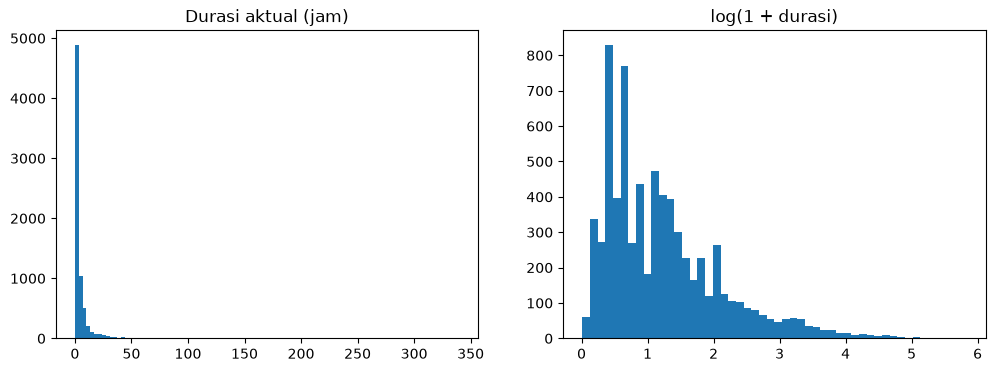

In [11]:
jam = sip_clean["HoursActual"]
print(jam.describe().round(2))

q1, q3 = jam.quantile([0.25, 0.75])
batas_iqr = q3 + 1.5 * (q3 - q1)
print("\nBatas atas IQR :", batas_iqr, "jam → dibuang:", (jam > batas_iqr).sum())
print("Batas domain 40 jam      → dibuang:", (jam > 40).sum())
print("Kurang dari 6 menit       :", (jam < 0.1).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(jam, bins=100)
ax[0].set_title("Durasi aktual (jam)")
ax[1].hist(np.log1p(jam), bins=50)
ax[1].set_title("log(1 + durasi)")
plt.show()

### Cleaning SiP 4: Outlier durasi
- Batas atas **40 jam** (pengetahuan domain), bukan IQR (9,5 jam). Data sangat
  right-skewed, dan tugas kuliah besar wajar dikerjakan 10–15 jam.
- Tugas > 40 jam terbukti berupa **proyek** (rentang median 48 hari,
  mis. "Tasks From Meeting"), bukan tugas tunggal. Tugas raksasa
  dipecah di sisi aplikasi.
- Batas bawah **0,1 jam (6 menit)**: data tidak akurat / bukan tugas sungguhan,
  dan terlalu kecil untuk dijadwalkan.
- Hasil: 7.176 → 7.037 baris.

In [12]:
sip_clean = sip_clean[(sip_clean["HoursActual"] >= 0.1) & (sip_clean["HoursActual"] <= 40)]
print(len(sip_clean))   # → 7037

7037


In [13]:
# Eksplorasi fitur: kolom SiP mana yang bisa jadi input PandAI?

print("=== Category:")
print(sip_clean["Category"].value_counts(), "\n")

print("=== SubCategory (15 teratas):")
print(sip_clean["SubCategory"].value_counts().head(15), "\n")

print("=== Priority:")
print(sip_clean["Priority"].value_counts().sort_index(), "\n")

# Apakah durasi beda-beda antar kategori?
print("=== Durasi per Category:")
print(sip_clean.groupby("Category")["HoursActual"]
      .agg(["count", "median", "mean"]).round(2).sort_values("median"), "\n")

# Seberapa kuat estimasi awal memprediksi durasi aktual?
rho = sip_clean["HoursEstimate"].corr(sip_clean["HoursActual"], method="spearman")
print("Korelasi Spearman HoursEstimate vs HoursActual:", round(rho, 3))

=== Category:
Category
Development    4754
Operational    1336
Management      947
Name: count, dtype: int64 

=== SubCategory (15 teratas):
SubCategory
Enhancement               1599
Bug                       1564
In House Support           861
Support                    824
Client Support             441
Release                    367
Marketing                  358
General Documentation      203
Management Meeting         142
Testing                    135
Training                   112
Project Management          57
Progress Meeting            54
Business Specification      46
Documentation               46
Name: count, dtype: int64 

=== Priority:
Priority
1     4336
2      569
3     1058
4      252
5      631
6       56
7       35
8       32
9       16
10      52
Name: count, dtype: int64 

=== Durasi per Category:
             count  median  mean
Category                        
Operational   1336    1.50  3.37
Development   4754    1.60  3.75
Management     947    2.75  4.93 

K

In [15]:
# Draft pemetaan SubCategory SiP -> type PandAI
peta_type = {
    "Enhancement": "coding", "Bug": "coding", "Release": "coding",
    "Conversion": "coding",
    "General Documentation": "laporan", "Documentation": "laporan",
    "Business Specification": "laporan", "Technical Specification": "laporan",
    "Research": "laporan",
    "Marketing": "presentasi", "Training": "presentasi",
    "Testing": "praktikum",
}

sip_model = sip_clean[sip_clean["SubCategory"].isin(peta_type.keys())].copy()
sip_model["type"] = sip_model["SubCategory"].map(peta_type)
print("Baris:", len(sip_clean), "→", len(sip_model), "\n")

print("=== Durasi per type:")
print(sip_model.groupby("type")["HoursActual"]
      .agg(["count", "median", "mean"]).round(2), "\n")

# size_level 1-3: posisi HoursEstimate di dalam type-nya sendiri (persentil)
pct = sip_model.groupby("type")["HoursEstimate"].rank(pct=True)
sip_model["size_level"] = np.select([pct <= 1/3, pct <= 2/3], [1, 2], default=3)

print("=== Median durasi per type x size_level:")
print(sip_model.groupby(["type", "size_level"])["HoursActual"].median().unstack().round(2))

Baris: 7037 → 4486 

=== Durasi per type:
            count  median  mean
type                           
coding       3541     2.0  4.17
laporan       340     2.7  7.45
praktikum     135     3.0  5.87
presentasi    470     3.0  4.02 

=== Median durasi per type x size_level:
size_level     1    2      3
type                        
coding      0.70  2.0   6.50
laporan     0.81  2.7  16.91
praktikum   1.00  3.5   7.50
presentasi  1.50  3.0   5.00


In [16]:
# === Bagian C · Pengali course_mastery dari OULAD ===
kunci_mk = ["id_student", "code_module", "code_presentation"]

oa = (data.dropna(subset=["score", "date"])
          .sort_values(kunci_mk + ["date"])
          .copy())
grp = oa.groupby(kunci_mk)

# Rata-rata nilai dari tugas-tugas SEBELUMNYA saja (tanpa tugas ini)
jumlah_skor_sebelumnya = grp["score"].cumsum() - oa["score"]
jumlah_tugas_sebelumnya = grp.cumcount()
oa["skor_sebelumnya"] = jumlah_skor_sebelumnya / jumlah_tugas_sebelumnya.replace(0, np.nan)
oa["deadline_sebelumnya"] = grp["date"].shift(1)

# Tugas pertama gak punya riwayat, jadi dibuang
oa = oa.dropna(subset=["skor_sebelumnya", "deadline_sebelumnya"])

oa["mastery"] = pd.cut(oa["skor_sebelumnya"], bins=[-1, 40, 60, 75, 90, 100],
                       labels=[1, 2, 3, 4, 5]).astype(int)
print("Baris:", len(oa))
print(oa["mastery"].value_counts().sort_index())

Baris: 141336
mastery
1     2975
2    12934
3    37955
4    68507
5    18965
Name: count, dtype: int64


In [17]:
vle = pd.read_csv(RAW / "studentVle.csv",
                  usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                  dtype={"code_module": "category", "code_presentation": "category",
                         "id_student": "int32", "date": "int16", "sum_click": "int32"})
print("studentVle:", f"{len(vle):,} baris")

# Ringkas jadi total klik per mahasiswa per hari, lalu jumlah kumulatifnya
harian = (vle.groupby(kunci_mk + ["date"], observed=True)["sum_click"].sum()
             .reset_index())
del vle
harian["kunci"] = harian["code_module"].astype(str) + "_" + harian["code_presentation"].astype(str)
harian = harian.sort_values(["id_student", "kunci", "date"])
harian["klik_kumulatif"] = harian.groupby(["id_student", "kunci"])["sum_click"].cumsum()
harian["date"] = harian["date"].astype("int64")

oa["kunci"] = oa["code_module"].astype(str) + "_" + oa["code_presentation"].astype(str)

def klik_sampai(df, kolom_hari):
    """Total klik kumulatif mahasiswa sampai hari tertentu."""
    kiri = (df[["id_student", "kunci", kolom_hari]]
              .rename(columns={kolom_hari: "date"})
              .astype({"date": "int64", "id_student": "int64"})
              .reset_index())
    kanan = harian[["id_student", "kunci", "date", "klik_kumulatif"]].astype({"id_student": "int64"})
    hasil = pd.merge_asof(kiri.sort_values("date"), kanan.sort_values("date"),
                          on="date", by=["id_student", "kunci"], direction="backward")
    return hasil.set_index("index")["klik_kumulatif"].reindex(df.index).fillna(0)

# Klik di antara deadline sebelumnya dan deadline tugas ini
oa["klik_jendela"] = klik_sampai(oa, "date") - klik_sampai(oa, "deadline_sebelumnya")
print(oa["klik_jendela"].describe().round(1))

studentVle: 10,655,280 baris
count    141336.0
mean        192.2
std         331.5
min           0.0
25%           0.0
50%          64.0
75%         232.0
max        7557.0
Name: klik_jendela, dtype: float64


In [18]:
# Hanya tugas yang benar-benar diselesaikan dengan lulus (seperti tugas di PandAI)
oa = oa[oa["score"] >= 40]

# Normalisasi: tiap tugas beda beban, jadi bandingkan dengan median tugas yang sama
median_per_tugas = oa.groupby("id_assessment")["klik_jendela"].transform("median")
oa = oa[median_per_tugas > 0].copy()
oa["rasio_usaha"] = oa["klik_jendela"] / median_per_tugas[median_per_tugas > 0]

ringkas = oa.groupby("mastery")["rasio_usaha"].agg(["count", "median"])
ringkas["pengali_vs_level3"] = ringkas["median"] / ringkas.loc[3, "median"]
print(ringkas.round(2))

rho = oa["skor_sebelumnya"].corr(oa["rasio_usaha"], method="spearman")
print("Spearman skor_sebelumnya vs rasio_usaha:", round(rho, 3))

         count  median  pengali_vs_level3
mastery                                  
1         2184    0.86               0.99
2         9001    0.78               0.91
3        24502    0.86               1.00
4        41718    1.05               1.21
5        14301    1.25               1.45
Spearman skor_sebelumnya vs rasio_usaha: 0.176


In [19]:
# Koreksi engagement: bandingkan tiap mahasiswa dengan kebiasaannya sendiri
kel = oa.groupby(kunci_mk)
oa["baseline_rajin"] = kel["rasio_usaha"].transform("median")
oa["n_tugas"] = kel["rasio_usaha"].transform("size")

w = oa[(oa["n_tugas"] >= 3) & (oa["baseline_rajin"] > 0)].copy()
w["usaha_relatif"] = w["rasio_usaha"] / w["baseline_rajin"]
w["usaha_relatif"] = w["usaha_relatif"].clip(upper=w["usaha_relatif"].quantile(0.99))
w["selisih_skor"] = w["skor_sebelumnya"] - w.groupby(kunci_mk)["skor_sebelumnya"].transform("mean")

print("Mahasiswa-matkul dianalisis:", w.groupby(kunci_mk).ngroups, "| baris:", len(w))

rk = w.groupby("mastery")["usaha_relatif"].agg(["count", "median", "mean"])
rk["pengali_vs_level3"] = rk["mean"] / rk.loc[3, "mean"]
print(rk.round(2))

rho_dalam = w["selisih_skor"].corr(w["usaha_relatif"], method="spearman")
print("Spearman DALAM mahasiswa yang sama:", round(rho_dalam, 3))

Mahasiswa-matkul dianalisis: 18102 | baris: 84890
         count  median  mean  pengali_vs_level3
mastery                                        
1         1529     1.0  1.14               1.02
2         7507     1.0  1.16               1.04
3        22435     1.0  1.12               1.00
4        39749     1.0  1.09               0.97
5        13670     1.0  1.10               0.98
Spearman DALAM mahasiswa yang sama: -0.006


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Fitur ukuran versi kontinu: posisi tugas di antara tugas sejenis (0-1)
sip_model["size_pct"] = sip_model.groupby("type")["HoursEstimate"].rank(pct=True)

y = sip_model["HoursActual"]
idx_train, idx_test = train_test_split(sip_model.index, test_size=0.2, random_state=42,
                                       stratify=sip_model["type"])
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("Train:", len(idx_train), "| Test:", len(idx_test), "\n")

def buat_pipeline(model):
    pra = ColumnTransformer([("type", OneHotEncoder(handle_unknown="ignore"), ["type"])],
                            remainder="passthrough")
    return Pipeline([("pra", pra), ("model", model)])

def skor(nama_fitur, nama_model, pred):
    return {"Fitur ukuran": nama_fitur, "Model": nama_model,
            "MAE (jam)": mean_absolute_error(y_test, pred),
            "RMSE (jam)": root_mean_squared_error(y_test, pred),
            "R²": r2_score(y_test, pred)}

hasil = []
for fitur_ukuran in ["size_level", "size_pct"]:
    X = sip_model[["type", fitur_ukuran]]
    X_train, X_test = X.loc[idx_train], X.loc[idx_test]

    # Baseline: tanpa ML, tebak median durasi per type
    med = y_train.groupby(X_train["type"]).median()
    hasil.append(skor(fitur_ukuran, "Baseline (median per type)", X_test["type"].map(med)))

    for nama, model in {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=42),
        "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    }.items():
        pipe = buat_pipeline(model)
        pipe.fit(X_train, np.log1p(y_train))          # latih di skala log
        pred = np.expm1(pipe.predict(X_test))         # kembalikan ke jam
        hasil.append(skor(fitur_ukuran, nama, pred))

print(pd.DataFrame(hasil).round(3).to_string(index=False))

Train: 3588 | Test: 898 

Fitur ukuran                      Model  MAE (jam)  RMSE (jam)     R²
  size_level Baseline (median per type)      3.302       6.408 -0.122
  size_level          Linear Regression      2.339       5.035  0.307
  size_level              Random Forest      2.252       4.900  0.344
  size_level          Gradient Boosting      2.252       4.902  0.343
    size_pct Baseline (median per type)      3.302       6.408 -0.122
    size_pct          Linear Regression      2.031       4.556  0.433
    size_pct              Random Forest      1.887       4.202  0.518
    size_pct          Gradient Boosting      1.862       4.129  0.534


In [21]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.compose import TransformedTargetRegressor

X = sip_model[["type", "size_pct"]]
X_train, X_test = X.loc[idx_train], X.loc[idx_test]

# Log transform dibungkus di dalam model: input jam, output jam
model_dasar = TransformedTargetRegressor(
    regressor=buat_pipeline(GradientBoostingRegressor(random_state=42)),
    func=np.log1p, inverse_func=np.expm1)

grid = {
    "regressor__model__n_estimators": [100, 200, 400],
    "regressor__model__learning_rate": [0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_samples_leaf": [10, 30],
}
cari = GridSearchCV(model_dasar, grid, cv=KFold(5, shuffle=True, random_state=42),
                    scoring="neg_mean_absolute_error", n_jobs=-1)
cari.fit(X_train, y_train)

print("Parameter terbaik:")
for k, v in cari.best_params_.items():
    print(f"  {k.split('__')[-1]:18s} = {v}")
print("MAE validasi silang (train):", round(-cari.best_score_, 3), "jam\n")

model_final = cari.best_estimator_
pred = model_final.predict(X_test)
print("=== Evaluasi di data TEST (belum pernah dilihat) ===")
print("MAE :", round(mean_absolute_error(y_test, pred), 3), "jam")
print("RMSE:", round(root_mean_squared_error(y_test, pred), 3), "jam")
print("R²  :", round(r2_score(y_test, pred), 3))

Parameter terbaik:
  learning_rate      = 0.05
  max_depth          = 4
  min_samples_leaf   = 30
  n_estimators       = 100
MAE validasi silang (train): 2.088 jam

=== Evaluasi di data TEST (belum pernah dilihat) ===
MAE : 1.885 jam
RMSE: 4.22 jam
R²  : 0.513


In [22]:
# Model kuantil: memprediksi batas bawah (persentil 10) dan atas (persentil 90)
params = {k.split("__")[-1]: v for k, v in cari.best_params_.items()}

def model_kuantil(alpha):
    gb = GradientBoostingRegressor(loss="quantile", alpha=alpha, random_state=42, **params)
    return TransformedTargetRegressor(regressor=buat_pipeline(gb),
                                      func=np.log1p, inverse_func=np.expm1)

model_min = model_kuantil(0.10).fit(X_train, y_train)
model_max = model_kuantil(0.90).fit(X_train, y_train)
p_min, p_max = model_min.predict(X_test), model_max.predict(X_test)

cakupan = ((y_test >= p_min) & (y_test <= p_max)).mean() * 100
print(f"Cakupan rentang (target 80%): {cakupan:.1f}%")
print(f"Lebar rentang: rata-rata {(p_max - p_min).mean():.2f} jam | median {np.median(p_max - p_min):.2f} jam\n")

contoh = pd.DataFrame({"type": X_test["type"].values,
                       "size_pct": X_test["size_pct"].round(2).values,
                       "min": p_min.round(1), "estimasi": pred.round(1),
                       "max": p_max.round(1), "aktual": y_test.values}).head(8)
print(contoh.to_string(index=False))

Cakupan rentang (target 80%): 78.7%
Lebar rentang: rata-rata 5.80 jam | median 2.61 jam

      type  size_pct  min  estimasi  max  aktual
    coding      0.49  1.1       1.9  3.5     2.1
presentasi      0.70  3.3       4.1  4.5     4.0
    coding      0.43  0.9       1.9  3.5     1.5
presentasi      0.50  2.8       3.2  3.5     3.0
    coding      0.08  0.3       0.5  0.8     0.5
    coding      0.08  0.3       0.5  0.8     1.0
    coding      0.81  1.7       5.1 11.3    14.7
    coding      0.08  0.3       0.5  0.8     0.5


In [23]:
import joblib, sklearn
from pathlib import Path
from datetime import datetime

PENGALI_MASTERY = {1: 1.30, 2: 1.15, 3: 1.00, 4: 0.90, 5: 0.80}   # asumsi (tulis di laporan)
RENTANG_UKURAN = {                                                  # asumsi tugas kuliah
    "laporan":    {"satuan": "halaman", "min": 1, "max": 30},
    "presentasi": {"satuan": "slide",   "min": 5, "max": 30},
    "coding":     {"satuan": "soal",    "min": 1, "max": 10},
    "praktikum":  {"satuan": "modul",   "min": 1, "max": 5},
}

paket = {
    "model_estimasi": model_final,
    "model_min": model_min,
    "model_max": model_max,
    "pengali_mastery": PENGALI_MASTERY,
    "rentang_ukuran": RENTANG_UKURAN,
    "metadata": {
        "versi": "v1-coldstart-sip",
        "dilatih_pada": datetime.now().isoformat(timespec="seconds"),
        "sklearn": sklearn.__version__,
        "fitur": ["type", "size_pct"],
        "hyperparameter": params,
        "evaluasi_test": {
            "MAE_jam": round(mean_absolute_error(y_test, pred), 3),
            "RMSE_jam": round(root_mean_squared_error(y_test, pred), 3),
            "R2": round(r2_score(y_test, pred), 3),
            "cakupan_rentang_persen": round(float(cakupan), 1),
        },
        "jumlah_data": {"train": len(idx_train), "test": len(idx_test)},
    },
}

folder = Path("../ml-service/models")
folder.mkdir(parents=True, exist_ok=True)
lokasi = folder / "pandai_model.pkl"
joblib.dump(paket, lokasi)
print("Tersimpan:", lokasi.resolve(), f"({lokasi.stat().st_size / 1024:.0f} KB)")
print(paket["metadata"])

Tersimpan: C:\Users\allan\Documents\GitHub\PandAI\ml-service\models\pandai_model.pkl (568 KB)
{'versi': 'v1-coldstart-sip', 'dilatih_pada': '2026-11-17T15:15:05', 'sklearn': '1.9.1', 'fitur': ['type', 'size_pct'], 'hyperparameter': {'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 30, 'n_estimators': 100}, 'evaluasi_test': {'MAE_jam': 1.885, 'RMSE_jam': 4.22, 'R2': 0.513, 'cakupan_rentang_persen': 78.7}, 'jumlah_data': {'train': 3588, 'test': 898}}


In [24]:
paket = joblib.load(lokasi)          # muat ulang, seolah-olah kita server FastAPI

PCT_BAWAH, PCT_ATAS = 0.20, 0.95

def ukuran_ke_pct(tipe, size):
    """Ubah angka size dari BE (mis. 10 halaman) jadi posisi 0.20-0.95."""
    r = paket["rentang_ukuran"][tipe]
    size = min(max(size, r["min"]), r["max"])
    posisi = (np.log(size) - np.log(r["min"])) / (np.log(r["max"]) - np.log(r["min"]))
    return PCT_BAWAH + (PCT_ATAS - PCT_BAWAH) * posisi

def prediksi(tipe, size, course_mastery):
    X_baru = pd.DataFrame({"type": [tipe], "size_pct": [ukuran_ke_pct(tipe, size)]})
    k = paket["pengali_mastery"][course_mastery]
    est = float(paket["model_estimasi"].predict(X_baru)[0]) * k
    lo = float(paket["model_min"].predict(X_baru)[0]) * k
    hi = float(paket["model_max"].predict(X_baru)[0]) * k
    lo, hi = min(lo, est), max(hi, est)
    pct = X_baru["size_pct"][0]
    faktor = ["Ukuran tugas " + ("besar" if pct > 2/3 else "sedang" if pct > 1/3 else "kecil"),
              "Pemahaman matkul " + {1: "sangat rendah", 2: "rendah", 3: "sedang",
                                     4: "baik", 5: "sangat baik"}[course_mastery]]
    return {"estimated_duration_hours": round(est, 1),
            "duration_range_hours": {"min": round(lo, 1), "max": round(hi, 1)},
            "factors": faktor}

for contoh in [("laporan", 10, 3), ("laporan", 10, 1), ("laporan", 25, 5),
               ("coding", 3, 3), ("presentasi", 15, 2), ("praktikum", 1, 4)]:
    print(contoh, "→", prediksi(*contoh))

('laporan', 10, 3) → {'estimated_duration_hours': 9.8, 'duration_range_hours': {'min': 2.1, 'max': 18.7}, 'factors': ['Ukuran tugas besar', 'Pemahaman matkul sedang']}
('laporan', 10, 1) → {'estimated_duration_hours': 12.8, 'duration_range_hours': {'min': 2.7, 'max': 24.3}, 'factors': ['Ukuran tugas besar', 'Pemahaman matkul sangat rendah']}
('laporan', 25, 5) → {'estimated_duration_hours': 14.4, 'duration_range_hours': {'min': 3.1, 'max': 26.3}, 'factors': ['Ukuran tugas besar', 'Pemahaman matkul sangat baik']}
('coding', 3, 3) → {'estimated_duration_hours': 2.8, 'duration_range_hours': {'min': 1.0, 'max': 6.2}, 'factors': ['Ukuran tugas sedang', 'Pemahaman matkul sedang']}
('presentasi', 15, 2) → {'estimated_duration_hours': 4.5, 'duration_range_hours': {'min': 3.8, 'max': 5.6}, 'factors': ['Ukuran tugas sedang', 'Pemahaman matkul rendah']}
('praktikum', 1, 4) → {'estimated_duration_hours': 1.2, 'duration_range_hours': {'min': 0.5, 'max': 2.2}, 'factors': ['Ukuran tugas kecil', 'Pema